# Case study: district questions with joins and window functions

*Session 3, block 2 · Author: course team · Licence: CC BY 4.0*

**Why.** The housing analyst now wants answers per district: which districts are the most expensive for each room
type, how did reviews develop in each district, how full are the calendars for the summer, and which listings never
receive a review? Each question combines tables (joins), summarises them (`GROUP BY`) or compares rows with their
group (window functions). The longer queries are kept as files in [`sql/`](sql/), so that a script, a notebook and
a database browser can run the same text.

**Steps**

1. Rank districts by price within each room type (`sql/02-rank-districts-by-price.sql`).
2. Reviews per district and year (join and `GROUP BY`).
3. Available nights in the summer per district and room type (join with the calendar, `HAVING`).
4. Reviews month by month: running totals and changes (`sql/03-reviews-running-total.sql`).
5. Who are the listings without any review? (left join)

In [1]:
import sqlite3
import subprocess
import sys
from pathlib import Path

import pandas as pd

# find the repository root (the folder that contains case-study/), wherever the notebook runs
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir())
DB = ROOT / "case-study" / "data" / "airbnb.sqlite"
if not DB.exists():   # build the course database once (needs case-study/prepare_airbnb.py to have run)
    subprocess.run([sys.executable, ROOT / "sessions/03-sql/workbooks/make_airbnb_sqlite.py"], check=True)

con = sqlite3.connect(DB)


def q(sql, params=()):
    """Run a query and return the result as a pandas DataFrame."""
    return pd.read_sql_query(sql, con, params=params)


q("SELECT (SELECT COUNT(*) FROM listings) AS listings, (SELECT COUNT(*) FROM calendar) AS calendar_rows, "
  "(SELECT COUNT(*) FROM reviews) AS review_months")


SQL_DIR = ROOT / "sessions" / "03-sql" / "workbooks" / "sql"

## 1. Rank districts by price within each room type

The query has three named steps (CTEs): the short stays with a price, one row per room type and district with at
least 30 listings, and the rank within each room type. `gap_to_top` puts the leader's average next to each
district with `MAX(...) OVER (PARTITION BY room_type)`.

In [2]:
print((SQL_DIR / "02-rank-districts-by-price.sql").read_text())

-- Rank Berlin districts by the average price of a short stay, separately for entire homes and
-- private rooms (common table expressions and a window function). Runs on the course database
-- case-study/data/airbnb.sqlite (SQLite 3.25 or newer) and unchanged on PostgreSQL.
-- Short stays: minimum stay below 28 nights and a price shown (the course convention).
-- Author: course team, licence CC BY 4.0

WITH short_stays AS (                      -- CTE 1: the listings the question is about
    SELECT district, room_type, price
    FROM listings
    WHERE minimum_nights < 28 AND price IS NOT NULL
      AND room_type IN ('Entire home/apt', 'Private room')
), per_district AS (                       -- CTE 2: one row per room type and district
    SELECT room_type, district,
           COUNT(*) AS n_listings,
           ROUND(AVG(price), 1) AS avg_price
    FROM short_stays
    GROUP BY room_type, district
    HAVING COUNT(*) >= 30                  -- no ranking on a handful of listings
), 

In [3]:
ranking = q((SQL_DIR / "02-rank-districts-by-price.sql").read_text())
ranking.pivot(index="district", columns="room_type", values="rnk").sort_values("Entire home/apt")

room_type,Entire home/apt,Private room
district,,
Spandau,1.0,9.0
Steglitz - Zehlendorf,2.0,7.0
Mitte,3.0,1.0
Charlottenburg-Wilm.,4.0,2.0
Pankow,5.0,3.0
Friedrichshain-Kreuzberg,6.0,4.0
Treptow - Köpenick,7.0,10.0
Tempelhof - Schöneberg,8.0,6.0
Lichtenberg,9.0,8.0


The order differs between the two markets: Spandau ranks first for entire homes (a small group with one extreme
price, see the lecture) but only ninth for private rooms, and Neukölln is tenth for entire homes but fifth for
private rooms. Marzahn-Hellersdorf has no rank for private rooms because it has fewer than 30 of them. A single
ranking over all listings would mix two markets.

## 2. Reviews per district and year

Each review month gets the district of its listing through the join. `substr(month, 1, 4)` takes the year from the
text date. The result has one row per district and year; pandas turns it into a table with one column per year.

In [4]:
reviews_by_year = q("""
SELECT l.district, substr(r.month, 1, 4) AS year, SUM(r.n_reviews) AS n_reviews
FROM listings AS l
JOIN reviews AS r ON r.listing_id = l.id
WHERE r.month BETWEEN '2019-01-01' AND '2025-12-01'
GROUP BY l.district, year
""")
reviews_by_year.pivot(index="district", columns="year", values="n_reviews").sort_values("2025", ascending=False).head(6)

year,2019,2020,2021,2022,2023,2024,2025
district,,,,,,,
Mitte,13284,6797,8450,17184,21081,26835,32541
Friedrichshain-Kreuzberg,12667,6107,8592,17143,21246,27164,31179
Pankow,10122,5241,6577,12694,14879,17472,21587
Charlottenburg-Wilm.,4457,2289,2881,5776,7020,10510,12827
Neukölln,3940,1583,1916,4509,6583,7724,8480
Tempelhof - Schöneberg,3755,1883,3080,5131,5680,8107,8354


All districts show the collapse of 2020 and the recovery from 2022. Remember that only listings still online in June
2026 contribute: listings that closed in between took their reviews with them, so the early years are undercounted.

## 3. Available nights in the summer per district and room type

`HAVING COUNT(*) >= 10000` keeps only combinations with at least 10,000 nights (about 160 listings over the 62 nights
of July and August), so that small groups do not top the list.

In [5]:
q("""
SELECT l.district, l.room_type, COUNT(*) AS nights, ROUND(AVG(c.available), 3) AS share_available
FROM listings AS l
JOIN calendar AS c ON c.listing_id = l.id
WHERE c.date BETWEEN '2026-07-01' AND '2026-08-31'
  AND l.room_type IN ('Entire home/apt', 'Private room')
GROUP BY l.district, l.room_type
HAVING COUNT(*) >= 10000
ORDER BY share_available
LIMIT 8
""")

,district,room_type,nights,share_available
0,Neukölln,Entire home/apt,48416,0.238
1,Friedrichshain-Kreuzberg,Private room,50382,0.276
2,Neukölln,Private room,30682,0.279
3,Pankow,Private room,25098,0.297
4,Pankow,Entire home/apt,92776,0.323
5,Friedrichshain-Kreuzberg,Entire home/apt,109056,0.332
6,Tempelhof - Schöneberg,Private room,16614,0.351
7,Lichtenberg,Entire home/apt,15226,0.357


A night that is not available is either **booked or blocked** by the host; the calendar does not say which. A low
share of available nights is therefore an upper bound on demand, not a measure of it.

## 4. Reviews month by month: running totals and changes

`SUM(...) OVER (PARTITION BY year ORDER BY month)` restarts the running total every January; `LAG` compares each
month with the previous one.

In [6]:
monthly = q((SQL_DIR / "03-reviews-running-total.sql").read_text())
monthly[monthly["month"].between("2020-01-01", "2020-12-01")]

,month,n_reviews,running_total_year,change_vs_previous_month
24,2020-01-01,3971,3971,-99.0
25,2020-02-01,4055,8026,84.0
26,2020-03-01,2512,10538,-1543.0
27,2020-04-01,285,10823,-2227.0
28,2020-05-01,612,11435,327.0
29,2020-06-01,1547,12982,935.0
30,2020-07-01,2681,15663,1134.0
31,2020-08-01,3743,19406,1062.0
32,2020-09-01,2871,22277,-872.0
33,2020-10-01,2344,24621,-527.0


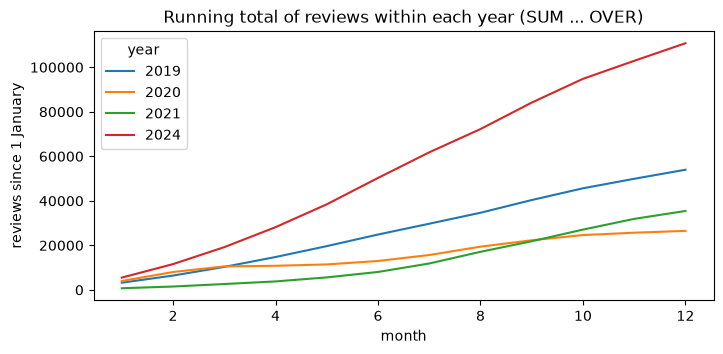

In [7]:
monthly["month"] = pd.to_datetime(monthly["month"])
ax = (monthly.assign(year=monthly["month"].dt.year, month_no=monthly["month"].dt.month)
      .query("year in [2019, 2020, 2021, 2024]")
      .pivot(index="month_no", columns="year", values="running_total_year")
      .plot(figsize=(8, 3.5), title="Running total of reviews within each year (SUM ... OVER)"))
ax.set(xlabel="month", ylabel="reviews since 1 January");

## 5. Who are the listings without any review?

A left join keeps all listings; `WHERE r.listing_id IS NULL` keeps those without a partner in `reviews`. Are they
different from the reviewed listings? A medium-term rental (minimum stay of 28 nights or more) is one candidate
explanation.

In [8]:
q("""
SELECT l.room_type, COUNT(*) AS n_without_review,
       ROUND(AVG(l.minimum_nights >= 28), 3) AS share_medium_term,
       ROUND(AVG(l.availability_365 = 0), 3) AS share_no_free_night
FROM listings AS l
LEFT JOIN reviews AS r ON r.listing_id = l.id
WHERE r.listing_id IS NULL
GROUP BY l.room_type
ORDER BY n_without_review DESC
""")

,room_type,n_without_review,share_medium_term,share_no_free_night
0,Entire home/apt,1912,0.823,0.259
1,Private room,648,0.664,0.426
2,Shared room,7,0.429,0.000
3,Hotel room,6,0.333,0.000


In [9]:
# for comparison: the same shares among the listings with at least one review
q("""
SELECT COUNT(*) AS n_with_review,
       ROUND(AVG(minimum_nights >= 28), 3) AS share_medium_term,
       ROUND(AVG(availability_365 = 0), 3) AS share_no_free_night
FROM listings WHERE number_of_reviews > 0
""")

,n_with_review,share_medium_term,share_no_free_night
0,10203,0.242,0.266


Most listings without a review are medium-term rentals: people who rent a flat for three months rarely leave a
review, or the listing is new. A report on "listings that nobody books" based on missing reviews would mostly
describe medium-term rentals.

**Summary.** Rankings within groups need a window function and a filter one level up; joins with one-to-many tables
must be read with the row count in mind; and every answer about demand from this snapshot inherits two limits: the
calendar does not separate booked from blocked nights, and the reviews come only from listings that still exist.